# **Identity Document Fraud Detection**
### Data Exploration

**AI Studio Challenge**  
**Industry Partner:** Verizon  
**Milestone:** September — Binary Classification  
**Dataset:** IDNet Identity Document Analysis Dataset

---



## **1. Project Overview**
The goal of our project is to develop a binary classification model that distinguishes between genuine and fake identity documents in the context of Verizon's customer onboarding process.  

In this notebook, we explore the IDNet dataset and prepare a manageable sample for further analysis.


## **2. Setup**
Import the libraries needed for dataset exploration, image processing, and visualization.

In [2]:
import os
import glob
import shutil
import zipfile
from collections import Counter

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

## **3. Dataset Exploration**

### 3.1 Upload & extract raw_sample.zip


In [1]:
from google.colab import files
uploaded = files.upload()

Saving raw_sample.zip to raw_sample.zip


In [3]:
with zipfile.ZipFile("raw_sample.zip", 'r') as z:
    z.extractall("/content/raw_sample")

print(f"Total files: {len(os.listdir('/content/raw_sample'))}")

Total files: 600


### 3.2 Dataset Structure (counts per category)


In [4]:
raw_dir = "/content/raw_sample"
all_files = os.listdir(raw_dir)

labels = ["drivers_license", "national_id", "passport"]
counts = Counter()
for f in all_files:
    for label in labels:
        if f.startswith(label):
            counts[label] += 1

for k, v in counts.items():
    print(f"{k}: {v} images")
print(f"Total: {sum(counts.values())}")

national_id: 200 images
drivers_license: 200 images
passport: 200 images
Total: 600


### 3.3 Image Properties (formats, dimensions)

In [5]:
formats, sizes, file_sizes_kb = [], [], []

for f in all_files:
    path = os.path.join(raw_dir, f)
    with Image.open(path) as im:
        formats.append(im.format)
        sizes.append(im.size)
    file_sizes_kb.append(os.path.getsize(path) / 1024)

print("Formats:", Counter(formats))
widths, heights = zip(*sizes)
print(f"Width range: {min(widths)}–{max(widths)}")
print(f"Height range: {min(heights)}–{max(heights)}")
print(f"Avg file size: {sum(file_sizes_kb)/len(file_sizes_kb):.1f} KB")

# Break down avg size per category (explains the WV vs RUS/GRC size difference)
for label in labels:
    matching = [f for f in all_files if f.startswith(label)]
    sizes_kb = [os.path.getsize(os.path.join(raw_dir, f)) / 1024 for f in matching]
    print(f"{label}: avg {sum(sizes_kb)/len(sizes_kb):.1f} KB ({len(matching)} images)")

Formats: Counter({'JPEG': 400, 'PNG': 200})
Width range: 1013–1519
Height range: 638–1069
Avg file size: 463.7 KB
drivers_license: avg 980.8 KB (200 images)
national_id: avg 199.7 KB (200 images)
passport: avg 210.7 KB (200 images)


### 3.4 Visualize sample genuine images

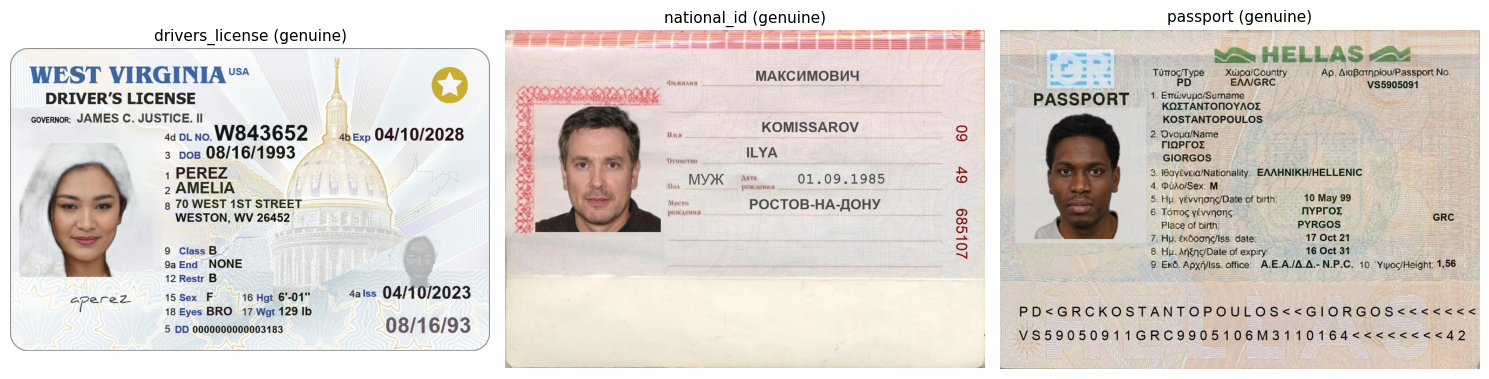

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, labels):
    matching = [f for f in all_files if f.startswith(label)]
    img = Image.open(os.path.join(raw_dir, matching[0]))
    ax.imshow(img)
    ax.set_title(f"{label} (genuine)", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

## **4. Synthetic Fake Generation**
### 4.1 Apply Gaussian blur to create fake subset

In [7]:
output_dir = "/content/final_sample"
os.makedirs(output_dir, exist_ok=True)

for label in labels:
    matching = [f for f in all_files if f.startswith(label)]
    genuine_files = matching[:100]
    to_blur_files = matching[100:200]

    for f in genuine_files:
        img = cv2.imread(os.path.join(raw_dir, f))
        cv2.imwrite(os.path.join(output_dir, f"{label}_genuine_{f}"), img)

    for f in to_blur_files:
        img = cv2.imread(os.path.join(raw_dir, f))
        blurred = cv2.GaussianBlur(img, (15, 15), 0)
        cv2.imwrite(os.path.join(output_dir, f"{label}_fake_{f}"), blurred)

print(f"Total in final_sample: {len(os.listdir(output_dir))}")

Total in final_sample: 600


### 4.2 Visualize genuine vs. fake side-by-side

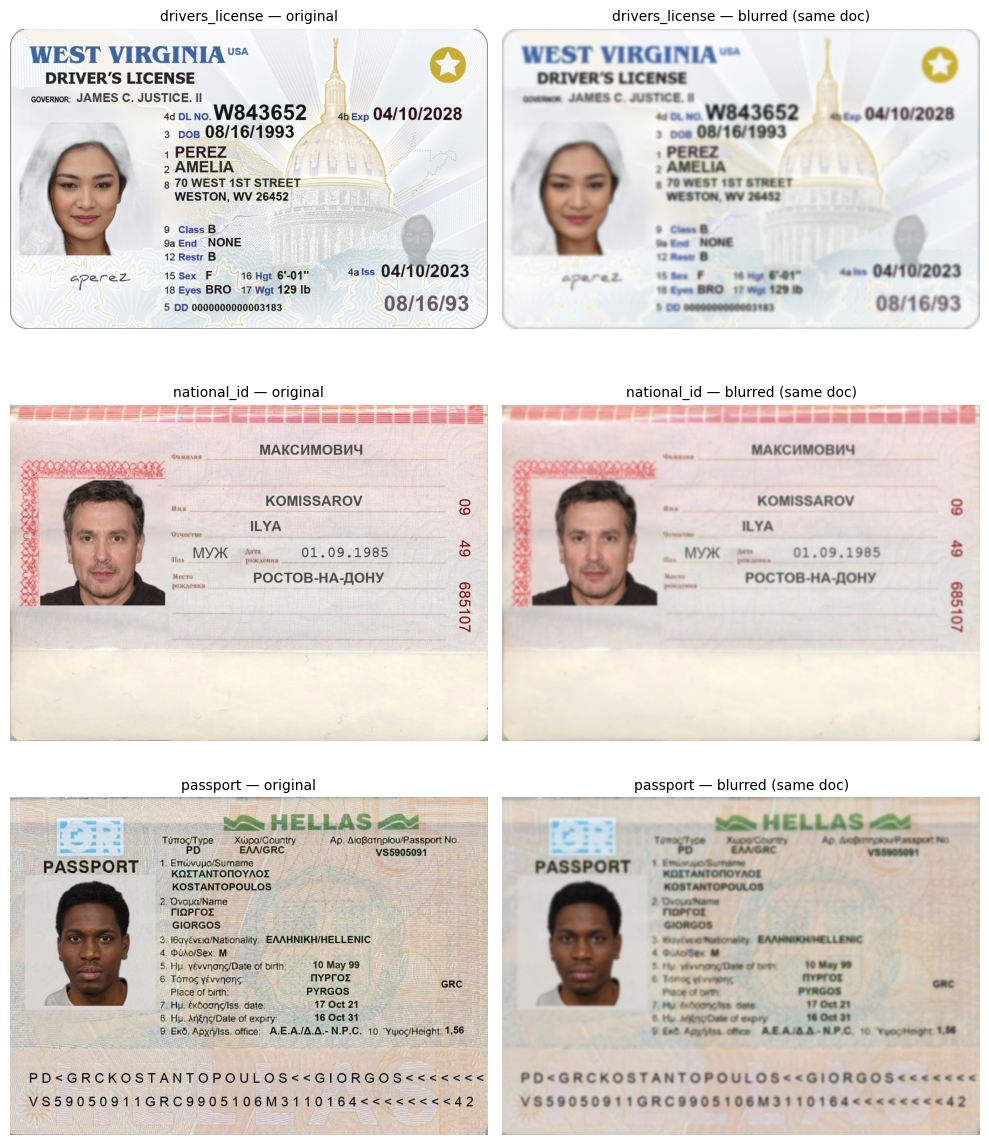

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for i, label in enumerate(labels):
    matching = [f for f in all_files if f.startswith(label)]
    sample_file = matching[0]  # same underlying document

    original_path = os.path.join(raw_dir, sample_file)
    img = cv2.imread(original_path)
    blurred = cv2.GaussianBlur(img, (15, 15), 0)

    # Convert BGR (OpenCV) to RGB for correct display in matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    blurred_rgb = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)

    axes[i, 0].imshow(img_rgb)
    axes[i, 0].set_title(f"{label} — original", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(blurred_rgb)
    axes[i, 1].set_title(f"{label} — blurred (same doc)", fontsize=10)
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### 4.3 Confirm final_sample: 600 total, labeled genuine/fake

In [12]:
final_files = os.listdir(output_dir)
final_counts = Counter()

for f in final_files:
    for label in labels:
        for kind in ["genuine", "fake"]:
            if f.startswith(f"{label}_{kind}"):
                final_counts[f"{label}_{kind}"] += 1

for k, v in final_counts.items():
    print(f"{k}: {v}")
print(f"Total: {sum(final_counts.values())}")

drivers_license_fake: 100
passport_genuine: 100
national_id_fake: 100
drivers_license_genuine: 100
passport_fake: 100
national_id_genuine: 100
Total: 600
